# Évora --> Distrito 15

In [ ]:
# Reiniciar o programa
#import os
#os.kill(os.getpid(),9)

In [35]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
import pickle 
from tqdm import tqdm
import numpy as np
from sklearn.metrics import mean_squared_error

df_15 = pd.read_csv('df_15_d.csv')
df_15_y = pd.read_csv('df_15_y_d.csv')

df_15['ID'] = [i for i in range(len(df_15))]
df_15_y['ID'] = [i for i in range(len(df_15_y))]

# Coluna = 'Unnamed: 0' --> corresponde aos id reais!! <-- IMP

In [36]:
df_15

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,2,2006,0.357143,True,0.16,0.10,f,0.428571,0.685003,-0.069626,0
1,6,2010,0.428571,True,0.50,0.32,b,0.428571,0.684572,-0.070132,1
2,7,True,0.428571,Swimming pool,0.18,0.18,d,0.142857,0.688347,-0.070647,2
3,13,True,0.285714,True,0.22,0.22,f,0.142857,0.684034,-0.075911,3
4,14,True,0.428571,True,0.40,0.40,e,0.571429,0.684572,-0.070132,4
...,...,...,...,...,...,...,...,...,...,...,...
1299,4471,True,0.285714,True,0.14,0.14,b,0.428571,0.688312,-0.073124,1299
1300,4472,1955,0.285714,True,0.18,0.10,f,0.428571,0.685222,-0.072149,1300
1301,4482,2010,0.285714,True,0.18,0.18,c,0.428571,0.689640,-0.073512,1301
1302,4485,True,0.214286,Garden,0.10,0.08,True,0.142857,0.681463,-0.073539,1302


# Pre-processamento 

### Colunas: 
- built_in
- amenities
- energetic_efficiency

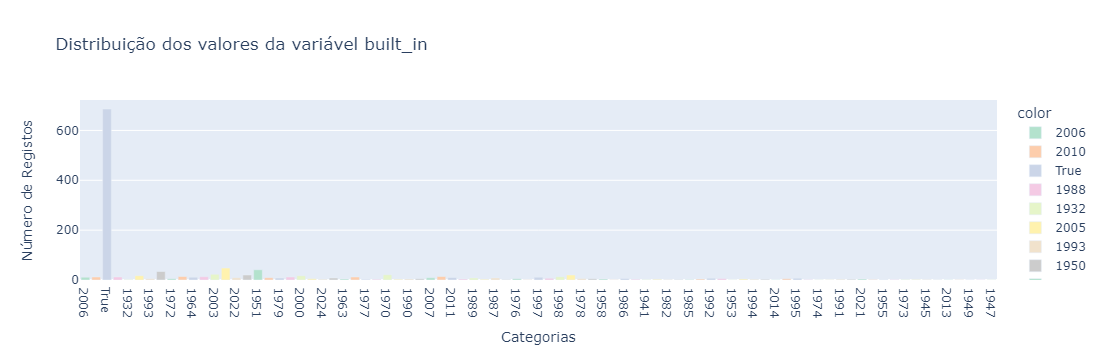

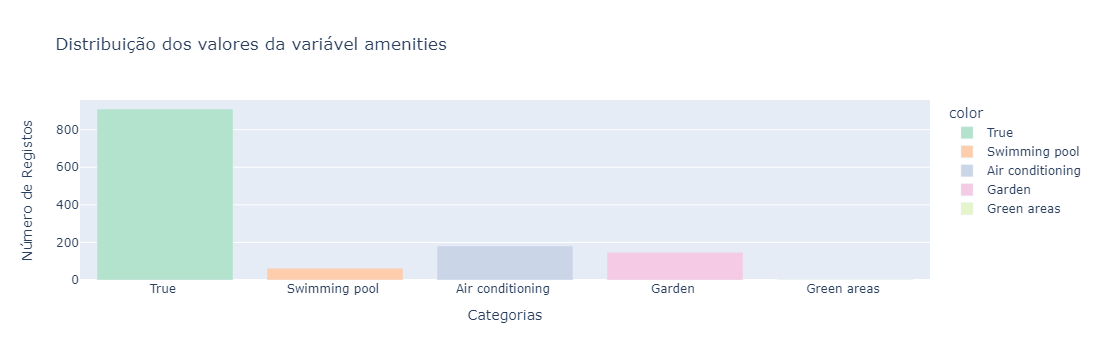

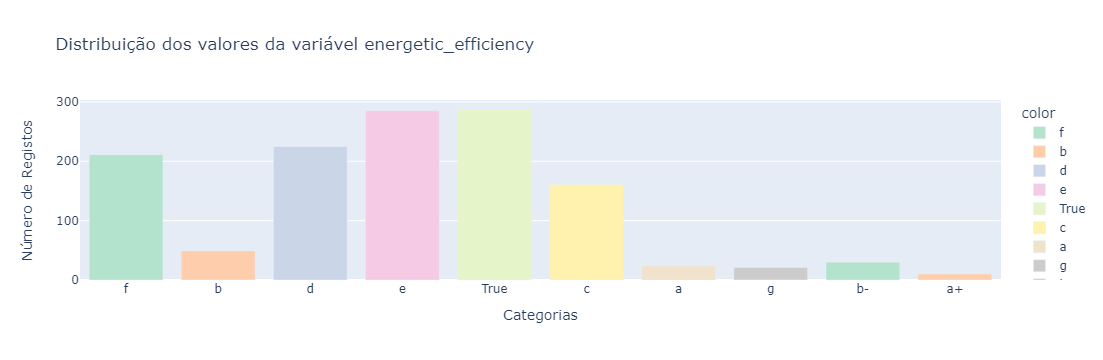

In [37]:
# Variação dos dados 
import plotly.express as px
col = ['built_in', 'amenities','energetic_efficiency']

for nome in col: 
    output = []
    names = df_15[nome].unique()
    for i in df_15[nome].unique():
        bt2 = df_15[nome].value_counts()[i]
        output.append(bt2)
    fig = px.bar(df_15, x=names, y=output, color = names ,color_discrete_sequence= px.colors.qualitative.Pastel2, title= f'Distribuição dos valores da variável {nome}')
    fig.update_xaxes(title_text='Categorias')
    fig.update_yaxes(title_text='Número de Registos')
    fig.show()

### --> Eficiência Energética

In [38]:
from sklearn.neighbors import KNeighborsClassifier
# Cluster para ver as casas mais parecidas, para depois asoociar um valor aos imóveis que não têm eficiencia energética

# Obter ID onde energetic_efficiency == 'True' e ou != 'True'
ids_true15 = list(df_15.loc[df_15['energetic_efficiency'] == 'True', 'ID']) # O que vão ser previstos 
ids_outros15 = list(df_15.loc[df_15['energetic_efficiency'] != 'True', 'ID'])

# Dados 
teste15 = df_15.loc[ids_true15,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
#teste_y15 = df_15.loc[ids_true15,['energetic_efficiency']]
treino15 = df_15.loc[ids_outros15,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
treino_y15 = df_15.loc[ids_outros15,['energetic_efficiency']]

# Comparação --> X_train_13[['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
def KNN(k, teste, treino, treino_y):
    knn =  KNeighborsClassifier(n_neighbors=k)
    knn.fit(treino, treino_y)
    y_pred = knn.predict(teste)
    return y_pred
l_ee15 = KNN(3, teste15, treino15, treino_y15)

# Substituir os True

def sub_ee(ids_true, l_ee, df, col):
    for i in range(len(ids_true)): 
        df.loc[df['ID'] == ids_true[i], col] = l_ee[i]
    return df
df_15 = sub_ee(ids_true15, l_ee15, df_15, 'energetic_efficiency')


ee15 = df_15.loc[:, ['energetic_efficiency']]

def substituir_energetic_efficiency(X):
    X = X.replace('a+', 1)
    X = X.replace('a', 2)
    X = X.replace('b', 3)
    X = X.replace('b-', 4)
    X = X.replace('c', 5)
    X = X.replace('d', 6)
    X = X.replace('e', 7)
    X = X.replace('f', 8)
    X = X.replace('g', 9)
    
    return X
ee15 = substituir_energetic_efficiency(ee15)

# normalizar valores 
def norm_ee(df1): 
    
    df1['energetic_efficiency'] = df1['energetic_efficiency'] /df1['energetic_efficiency'].abs().max()
    return df1
ee15 = norm_ee(ee15)

df_15['energetic_efficiency'] = ee15

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



### --> Amenities

In [39]:
aa15 = df_15.loc[:, ['amenities']]

def substituir_amenities(X):
    X = X.replace('True ', 1)
    X = X.replace('Air conditioning ', 2)
    X = X.replace('Garden ', 3)
    X = X.replace('Green areas ', 3)
    X = X.replace('Swimming pool ', 4)
    
    return X
aa15 = substituir_amenities(aa15)

# normalizar valores 
def norm_amenities(df1): 
    
    df1['amenities'] = df1['amenities'] /11
    return df1
aa15 = norm_amenities(aa15)

df_15['amenities'] = aa15

### --> built_in

In [40]:
id_true15 = list(df_15.loc[df_15['built_in'] == 'True', 'ID'])
id_outros15 = list(df_15.loc[df_15['built_in'] != 'True', 'ID'])

# Obter anos que têm menos de 2 samples 

def menos_2(df, nome): 
    l = []
    for i in df[nome].unique():
        bt2 = df[nome].value_counts()[i]
        if bt2 < 3: 
            l.append(i) 
    return l
lista_data15 = menos_2(df_15, 'built_in')

def replicação_menos2(df, lista_data, id_outros):
    for ano in lista_data: 
        id_ano = list(df.loc[df['built_in'] == ano, 'ID'])
        for i in range(len(id_ano)):
            id_outros.append(id_ano[i])
            id_outros.append(id_ano[i])
    return id_outros

id_outros15 = replicação_menos2(df_15, lista_data15, id_outros15)

# Dados 
# criar dataset com price

d_b15 =  df_15.loc[:,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
d_b_215 = df_15_y.loc[:,['Price_norm']]
#d_b = pd.concat([d_b_1, d_b_2])
d_b15 = d_b15.join(d_b_215)


teste_b15 = d_b15.loc[id_true15,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
#teste_y15 = df_15.loc[ids_true15,['built_in']]
treino_b15 = d_b15.loc[id_outros15,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
treino_b_y15 = df_15.loc[id_outros15,['built_in']]

# KNN
l_b_i15 = KNN(3, teste_b15, treino_b15, treino_b_y15)

# Substituir
df_15 = sub_ee(id_true15, l_b_i15, df_15, 'built_in')

b_i15 = df_15.loc[:, ['built_in']]
b_i15['built_in'] = b_i15['built_in'].astype(int)

# normalizar valores 
def norm_b_i(df1): 
    
    df1['built_in'] = df1['built_in'] /2024
    return df1
b_i15 = norm_b_i(b_i15)

df_15['built_in'] = b_i15

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



In [41]:
df_15

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,2,0.991107,0.357143,0.090909,0.16,0.10,0.888889,0.428571,0.685003,-0.069626,0
1,6,0.993083,0.428571,0.090909,0.50,0.32,0.333333,0.428571,0.684572,-0.070132,1
2,7,0.966403,0.428571,0.363636,0.18,0.18,0.666667,0.142857,0.688347,-0.070647,2
3,13,0.970356,0.285714,0.090909,0.22,0.22,0.888889,0.142857,0.684034,-0.075911,3
4,14,0.985672,0.428571,0.090909,0.40,0.40,0.777778,0.571429,0.684572,-0.070132,4
...,...,...,...,...,...,...,...,...,...,...,...
1299,4471,0.970356,0.285714,0.090909,0.14,0.14,0.333333,0.428571,0.688312,-0.073124,1299
1300,4472,0.965909,0.285714,0.090909,0.18,0.10,0.888889,0.428571,0.685222,-0.072149,1300
1301,4482,0.993083,0.285714,0.090909,0.18,0.18,0.555556,0.428571,0.689640,-0.073512,1301
1302,4485,0.963439,0.214286,0.272727,0.10,0.08,0.777778,0.142857,0.681463,-0.073539,1302


# Modelo

In [42]:

# Dividir em treino e teste

X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(df_15, df_15_y, test_size=0.30, random_state=42)
X_train_15

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
676,2286,0.982213,0.214286,0.090909,0.08,0.08,0.888889,0.285714,0.689820,-0.074203,676
554,1864,0.958004,1.000000,0.363636,0.04,0.04,0.777778,0.571429,0.690674,-0.069841,554
825,2815,0.963933,0.500000,0.272727,0.28,0.26,0.777778,0.142857,0.679957,-0.073475,825
785,2670,0.986660,0.500000,0.181818,0.30,0.30,0.555556,0.571429,0.683824,-0.076059,785
887,3030,0.988636,0.357143,0.090909,0.18,0.16,0.666667,0.428571,0.683952,-0.075844,887
...,...,...,...,...,...,...,...,...,...,...,...
1095,3737,0.921937,0.285714,0.272727,0.30,0.30,0.555556,0.285714,0.687139,-0.073595,1095
1130,3861,0.971838,0.500000,0.090909,0.24,0.20,0.888889,0.428571,0.688546,-0.070265,1130
1294,4450,0.974308,0.357143,0.090909,0.30,0.14,0.777778,0.428571,0.693963,-0.075176,1294
860,2944,0.992095,0.285714,0.181818,0.16,0.16,0.444444,0.285714,0.684572,-0.070132,860


In [43]:
X_train15 = X_train_15[['tipology', 'amenities', 'built_in','energetic_efficiency', 'house_type']]
X_test15 = X_test_15[[ 'tipology', 'amenities', 'built_in', 'energetic_efficiency', 'house_type']]
y_train15 = y_train_15[['Price_norm']]
y_test15 = y_test_15[['Price_norm']]

# Gradient Boosting Regresso

In [45]:
"""
from sklearn import ensemble

gbd = ensemble.GradientBoostingRegressor(n_estimators = 300, max_depth = 10, min_samples_split = 2, learning_rate = 0.005, loss = 'squared_error')
gbd.fit(X_train15, y_train15)
y_pred_15 = gbd.predict(X_test15)
y_pred_15 = [abs(x) for x in y_pred_15]
#print(y_pred_15)
print(mean_squared_error(y_pred_15,y_test15))
print(gbd.score(X_test15,y_test15))

### Guardar o modelo

import pickle

with open('modelo_dist15.pkl', 'wb') as file:
    pickle.dump(gbd, file)
"""


C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\ensemble\_gb.py:424: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



0.0010253937470200672
0.5101856698787803


In [46]:
# abrir modelo

with open('modelo_dist15.pkl', 'rb') as f:
    GBD = pickle.load(f)
GBD

GradientBoostingRegressor(learning_rate=0.005, max_depth=10, n_estimators=300)

In [47]:
y_prev = GBD.predict(X_test15)

# OUTPUT E VIS

In [48]:
y_test15['prev_norm'] = y_prev

C:\Users\User\AppData\Local\Temp\ipykernel_13148\865910231.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [49]:
# Desnormalizar valores e Criar 'Price_prev'
def desnormalizar(valor):
    maximoout= 15000000 # depois mudar este valor, para o verdadeiro máximo
    return np.round(valor * maximoout,0)

def lista_des(lista): 
    n_l = []
    for i in lista: 
        n_l.append(desnormalizar(i))
    return n_l

y_test15['Price_prev'] = lista_des(y_prev)

def df_criar_id(y_test, df_13_y):
    y_test['Price_Real'] =[0] * len(y_test)
    for i in y_test.index:
        y_test['Price_Real'][i] = df_13_y['Price_Real'].iloc[i]
    return y_test
y_test15 = df_criar_id(y_test15, df_15_y)

C:\Users\User\AppData\Local\Temp\ipykernel_13148\3716328122.py:12: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_13148\3716328122.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_13148\3716328122.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_

In [50]:
# Crirar intervalo de preço

def intervalo_preco(y):
    l =  []
    for i in y['Price_prev']: 
        p_int = [i-(i*0.03), i+(i*0.03)]
        l.append(p_int)
    y['Price_Prev_Int'] = l
    return y

y_test15 =  intervalo_preco(y_test15)

In [51]:
y_test15

,Price_norm,prev_norm,Price_prev,Price_Real,Price_Prev_Int
1172,0.032667,0.016862,252935.0,490000,"[245346.95, 260523.05]"
514,0.011100,0.024613,369198.0,166500,"[358122.06, 380273.94]"
843,0.005000,0.014279,214187.0,75000,"[207761.39, 220612.61]"
977,0.019333,0.014279,214187.0,290000,"[207761.39, 220612.61]"
1168,0.023333,0.015623,234339.0,350000,"[227308.83, 241369.17]"
...,...,...,...,...,...
636,0.010333,0.019281,289213.0,155000,"[280536.61, 297889.39]"
462,0.014000,0.033880,508204.0,210000,"[492957.88, 523450.12]"
806,0.024333,0.020292,304376.0,365000,"[295244.72, 313507.28]"
990,0.038667,0.025503,382538.0,580000,"[371061.86, 394014.14]"


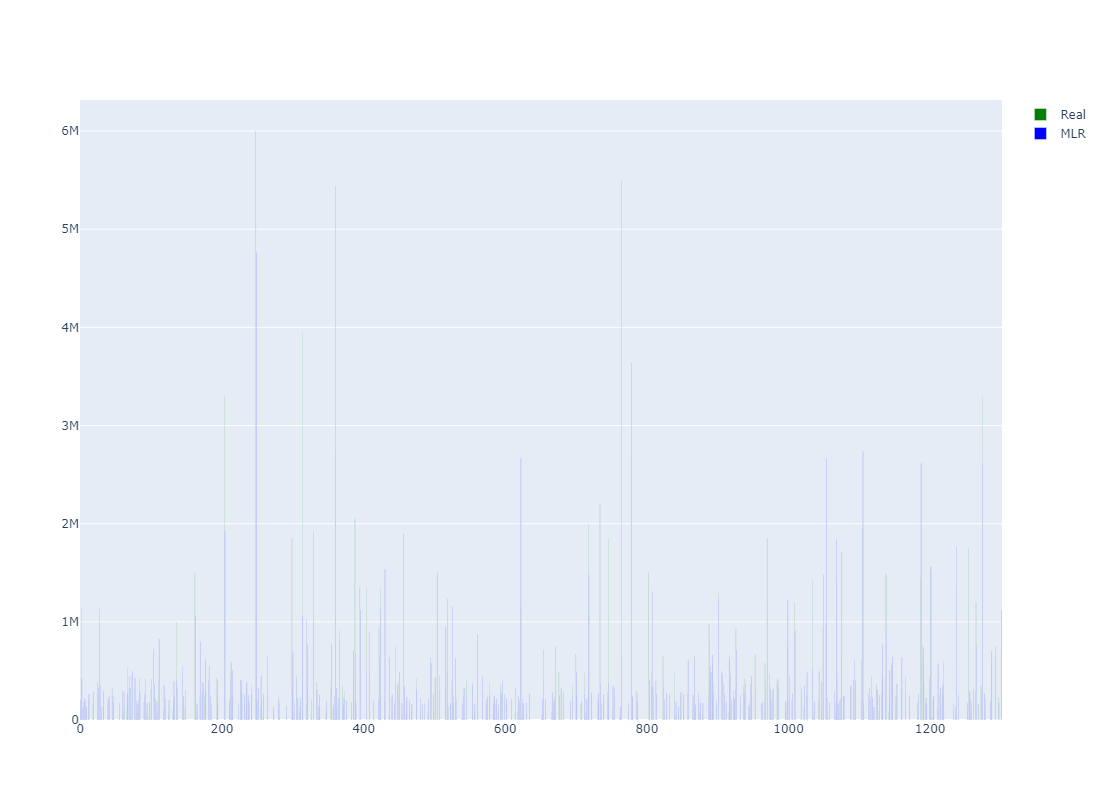

In [52]:
import plotly.graph_objects as go

# Grafico preço real e valor previsto
fig = go.Figure(
    data=[
        go.Bar(x=X_train_15.ID, y=y_test15.Price_Real, name="Real", marker_color='green'),
        go.Bar(x=X_train_15.ID, y=y_test15.Price_prev, name="MLR",  marker_color='blue'),
    ],
)
fig.update_layout(
    autosize=False,
    width=1000,
    height=800)

fig.show()